# v14: Wu + Berke, CE + lambda x population beta loss (v8 regime), Kev 4B

**Comparison with v12** (`train-beta-v12-wu-berke-scale-4b`: v8's settings on Kev 4B with v8's sample beta loss). Same
model, data, sample size, LR, epochs, seed, validators and best.pt rule as v12; only the beta term changes: the sample
beta loss is replaced by the population beta loss. Benchmarks: v12's CE-only run (lambda = 0) and its sample-loss runs
(lambda = 0.25 and 1). The 800M version of this notebook is the v8 comparison.

In [1]:
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "training"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and training/ at or above {Path.cwd()}")

# The `beta_ols`, `beta_train` and `beta_ce_population` packages live next to this notebook in `train-notebooks/beta-training/`
BETA_TRAINING_DIR = CODE_DIR / "train-notebooks" / "beta-training"
if not (BETA_TRAINING_DIR / "beta_ce_population").is_dir():
    raise RuntimeError(f"`beta_ce_population` package not found in {BETA_TRAINING_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and the beta-training folder on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(BETA_TRAINING_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_ce_population.config import CEPopulationTrainConfig
from beta_ce_population.trainer import load_ce_population_run, run_ce_population_training
from beta_train.config import scale_lr_for_sample_size
from beta_train.diagnostics import find_max_micro_chunk
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import set_checkpointing, snapshot_trainable
from beta_train.trainer import load_run
from beta_train.validation import PopulationValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 4B backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to train jaredpalmer/kev-4b in bf16")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-4b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0
# Recompute activations in backward (less VRAM, slower). Memory-only: not part of a run's identity. Set True if the
# micro-chunk search below finds no size that fits
GRADIENT_CHECKPOINTING = False

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
set_checkpointing(kev_model, GRADIENT_CHECKPOINTING)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "gradient_checkpointing": GRADIENT_CHECKPOINTING,
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_4b_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run and the step-0 validation start from them
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

,kev_4b_train_mode
base_model,jaredpalmer/kev-4b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"131,170,816"
total_params,"4,336,922,112"
gradient_checkpointing,False
model_load_sec,2.582


Snapshotted 500 trainable tensors


# Datasets (loaded and replicated through `beta_ols`)

In [3]:
# v8's design: train on Wu and Berke (CE on their y, plus their population betas), validate on the held-out Kriner
# and Grummon 2025
ITEM_DATASETS = [         # training items are built for these
    "wu2025",
    "berke2023",
]
VALIDATION_DATASETS = [   # validation runs on these
    "kriner2026",
    "grummon2025",
]
LOADED_DATASETS = list(ITEM_DATASETS)
for dataset_name in VALIDATION_DATASETS:
    if dataset_name not in LOADED_DATASETS:
        LOADED_DATASETS.append(dataset_name)

# Load each through its `beta_ols` module: task rows, regression rows, regression specs, human OLS replication.
# Training uses one piece per task variable: Wu is one piece (its own name), Berke four (one per delivery task).
choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}    # (pseudo) dataset name -> the beta_ols module that codes its rows
TRAIN_DATASETS = []       # pseudo datasets of ITEM_DATASETS, the names training uses

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        TRAIN_DATASETS.extend(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | {len(choice_df):,} tasks | {len(specs)} regression(s)")
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))
print(f"TRAIN_DATASETS = {TRAIN_DATASETS}")

wu2025: 1,861 respondents | 18,591 tasks | 1 regression(s)


wu2025                 
                                              beta      se std_beta
Monthly bill: $110 vs $105                 -0.0969  0.0078  -0.1938
Monthly bill: $115 vs $105                 -0.1779  0.0084  -0.3559
Monthly bill: $120 vs $105                 -0.2894  0.0092  -0.5789
Monthly bill: $125 vs $105                 -0.3832  0.0100  -0.7664
Percentage of renewables: 30% vs 10%        0.0973  0.0073   0.1946
Percentage of renewables: 50% vs 10%        0.1706  0.0081   0.3413
Percentage of renewables: 100% vs 10%       0.2421  0.0096   0.4842
Locally produced renewables: Yes vs No      0.1042  0.0056   0.2085
sigma_y                                     0.5000     NaN      NaN
n_rows                                  37182.0000     NaN      NaN

berke2023/delivery_choice_v0: 3,014 respondents | 9,528 tasks | 1 regression(s)


berke2023/v0                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.1607  0.0095   0.3214
Fee L1 vs $0 ($1)                       -0.1509  0.0088  -0.3018
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3298  0.0102  -0.6595
Fee L3 vs $0 ($5 fast / $10 meds)       -0.4978  0.0108  -0.9956
Wait L1 vs L0 (20m fast / 2h meds)      -0.0631  0.0107  -0.1261
Wait L2 vs L0 (30m fast / 6h meds)      -0.2082  0.0106  -0.4164
Wait L3 vs L0 (45m fast / 1d meds)      -0.3419  0.0124  -0.6837
sigma_y                                  0.5000     NaN      NaN
n_rows                               19056.0000     NaN      NaN

berke2023/delivery_choice_v1: 3,323 respondents | 11,481 tasks | 1 regression(s)


berke2023/v1                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.2242  0.0088   0.4484
Fee L1 vs $0 ($1)                       -0.0822  0.0087  -0.1644
Fee L2 vs $0 ($3 fast / $5 meds)        -0.2964  0.0096  -0.5929
Fee L3 vs $0 ($5 fast / $10 meds)       -0.5023  0.0108  -1.0045
Wait L1 vs L0 (20m fast / 2h meds)      -0.0743  0.0095  -0.1487
Wait L2 vs L0 (30m fast / 6h meds)      -0.1924  0.0095  -0.3848
Wait L3 vs L0 (45m fast / 1d meds)      -0.2638  0.0102  -0.5276
sigma_y                                  0.5000     NaN      NaN
n_rows                               22962.0000     NaN      NaN

... (5 outputs left out)

kriner2026                 
                                       beta      se std_beta
Airline: Frontier                   -0.0854  0.0137  -0.1709
Airline: Southwest                  -0.0238  0.0139  -0.0476
Airline: United                     -0.0220  0.0132  -0.0440
Fuel: Sustainable aviation fuel      0.0691  0.0105   0.1381
Baggage: Checked bag+carry-on        0.0561  0.0124   0.1121
Baggage: Personal item only         -0.1393  0.0122  -0.2785
Space: Extra legroom                 0.0653  0.0097   0.1305
Seat: Middle                        -0.0906  0.0127  -0.1813
Seat: Window                         0.0384  0.0124   0.0769
Price: $275                         -0.0853  0.0137  -0.1705
Price: $300                         -0.1953  0.0142  -0.3907
Price: $325                         -0.3040  0.0143  -0.6080
sigma_y                              0.5000     NaN      NaN
n_rows                           10000.0000     NaN      NaN

grummon2025: 5,633 respondents | 33,798 tasks | 1 regression(s)


grummon2025                 
                                          beta      se std_beta
NutritionInfo vs Positive               0.1844  0.0119   0.4196
HighIn vs Positive                      0.0541  0.0122   0.1231
Positive+NutritionInfo vs Positive      0.1788  0.0120   0.4069
Positive+HighIn vs Positive             0.1194  0.0122   0.2718
Spectrum vs Positive                    0.1083  0.0125   0.2464
sigma_y                                 0.4395     NaN      NaN
n_rows                              33798.0000     NaN      NaN

TRAIN_DATASETS = ['wu2025', 'berke2023/delivery_choice_v0', 'berke2023/delivery_choice_v1', 'berke2023/delivery_choice_v2', 'berke2023/delivery_choice_v3']


# Population beta targets (standardized human population betas of each training piece)

In [4]:
# One target vector per training piece and regression: the standardized human population betas (beta / sigma),
# in the spec's target order, from the human OLS replication of that piece (a published-table stand-in)
target_std_betas_by_dataset = {}
for dataset_name in TRAIN_DATASETS:
    dataset_ols = human_ols_by_dataset[dataset_name]
    dataset_targets = {}
    for group, spec in regression_specs_by_dataset[dataset_name].items():
        group_ols = dataset_ols[dataset_ols["model"] == group].set_index("term")
        target_values = group_ols.loc[spec.target_labels, "std_beta"].to_numpy(dtype=np.float64)
        dataset_targets[group] = torch.tensor(target_values, dtype=torch.float64)
    target_std_betas_by_dataset[dataset_name] = dataset_targets

for dataset_name, dataset_targets in target_std_betas_by_dataset.items():
    for group, target in dataset_targets.items():
        labels = regression_specs_by_dataset[dataset_name][group].target_labels
        display(pd.Series(target.numpy(), index=labels, name=f"{dataset_name} | {group} target std beta").round(4).to_frame())

,wu2025 | wu2025 target std beta
Monthly bill: $110 vs $105,-0.1938
Monthly bill: $115 vs $105,-0.3559
Monthly bill: $120 vs $105,-0.5789
Monthly bill: $125 vs $105,-0.7664
Percentage of renewables: 30% vs 10%,0.1946
Percentage of renewables: 50% vs 10%,0.3413
Percentage of renewables: 100% vs 10%,0.4842
Locally produced renewables: Yes vs No,0.2085


,berke2023/delivery_choice_v0 | berke2023/v0 target std beta
v0: take-out food | Drone privacy: YES vs NO,0.3214
v0: take-out food | Fee L1 vs $0 ($1),-0.3018
v0: take-out food | Fee L2 vs $0 ($3 fast / $5 meds),-0.6595
v0: take-out food | Fee L3 vs $0 ($5 fast / $10 meds),-0.9956
v0: take-out food | Wait L1 vs L0 (20m fast / 2h meds),-0.1261
v0: take-out food | Wait L2 vs L0 (30m fast / 6h meds),-0.4164
v0: take-out food | Wait L3 vs L0 (45m fast / 1d meds),-0.6837


,berke2023/delivery_choice_v1 | berke2023/v1 target std beta
v1: prescription medications | Drone privacy: YES vs NO,0.4484
v1: prescription medications | Fee L1 vs $0 ($1),-0.1644
v1: prescription medications | Fee L2 vs $0 ($3 fast / $5 meds),-0.5929
v1: prescription medications | Fee L3 vs $0 ($5 fast / $10 meds),-1.0045
v1: prescription medications | Wait L1 vs L0 (20m fast / 2h meds),-0.1487
v1: prescription medications | Wait L2 vs L0 (30m fast / 6h meds),-0.3848
v1: prescription medications | Wait L3 vs L0 (45m fast / 1d meds),-0.5276


,berke2023/delivery_choice_v2 | berke2023/v2 target std beta
v2: liquor store | Drone privacy: YES vs NO,0.4215
v2: liquor store | Fee L1 vs $0 ($1),-0.3068
v2: liquor store | Fee L2 vs $0 ($3 fast / $5 meds),-0.6503
v2: liquor store | Fee L3 vs $0 ($5 fast / $10 meds),-1.0537
v2: liquor store | Wait L1 vs L0 (20m fast / 2h meds),-0.0484
v2: liquor store | Wait L2 vs L0 (30m fast / 6h meds),-0.3043
v2: liquor store | Wait L3 vs L0 (45m fast / 1d meds),-0.5545


,berke2023/delivery_choice_v3 | berke2023/v3 target std beta
v3: last-minute groceries | Drone privacy: YES vs NO,0.4277
v3: last-minute groceries | Fee L1 vs $0 ($1),-0.3318
v3: last-minute groceries | Fee L2 vs $0 ($3 fast / $5 meds),-0.7216
v3: last-minute groceries | Fee L3 vs $0 ($5 fast / $10 meds),-1.1580
v3: last-minute groceries | Wait L1 vs L0 (20m fast / 2h meds),-0.1417
v3: last-minute groceries | Wait L2 vs L0 (30m fast / 6h meds),-0.4369
v3: last-minute groceries | Wait L3 vs L0 (45m fast / 1d meds),-0.6919


# Validators and training items

In [5]:
# One fused validator per VALIDATION_DATASETS entry (population OLS from the dataset's module)
# Per-GPU-batch inference budgets: lower them if validation runs out of memory, raise for speed
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000

validators = {}
for dataset_name in VALIDATION_DATASETS:
    validators[dataset_name] = PopulationValidator(
        beta_ols.DATASET_MODULES[dataset_name],
        choice_dfs[dataset_name],
        regression_specs_by_dataset[dataset_name],
        max_questions=VALIDATION_MAX_QUESTIONS,
        max_chars=VALIDATION_MAX_CHARS,
    )
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,graph_limits,prep_sec
validator,,,,,,,,
kriner2026,fused,5000,990,kriner2026,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",0.792
grummon2025,fused,33798,4906,grummon2025,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",6.523


In [6]:
# Untrained (step-0) validation, loaded from the disk cache when it already ran for this model, data, and code;
# reused as the first validation row of every run
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for dataset_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

,source
validator,
kriner2026,cache
grummon2025,cache


,kriner2026,grummon2025
kl_loss,0.8107,1.0998
beta_mse,0.0041,0.0211
beta_mae,0.0513,0.1233
beta_mape_pct,63.9489,146.0585
spearman_rho,0.8951,0.8000
eval_prep_sec,0.0542,0.5373
eval_gpu_sec,38.2256,313.7828
eval_wall_sec,40.5354,317.6025
eval_ms_per_task,8.1071,9.3971


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Airline: Frontier,kriner2026,-0.0854,-0.1804,-0.0950,0.0950
Airline: Southwest,kriner2026,-0.0238,0.0220,0.0458,0.0458
Airline: United,kriner2026,-0.0220,-0.0166,0.0054,0.0054
Fuel: Sustainable aviation fuel,kriner2026,0.0691,0.0995,0.0305,0.0305
Baggage: Checked bag+carry-on,kriner2026,0.0561,0.0877,0.0316,0.0316
Baggage: Personal item only,kriner2026,-0.1393,-0.1861,-0.0468,0.0468
Space: Extra legroom,kriner2026,0.0653,0.1244,0.0592,0.0592
Seat: Middle,kriner2026,-0.0906,-0.0841,0.0065,0.0065
Seat: Window,kriner2026,0.0384,0.0087,-0.0297,0.0297


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
NutritionInfo vs Positive,grummon2025,0.1844,0.2495,0.0651,0.0651
HighIn vs Positive,grummon2025,0.0541,-0.2079,-0.2620,0.2620
Positive+NutritionInfo vs Positive,grummon2025,0.1788,0.3053,0.1265,0.1265
Positive+HighIn vs Positive,grummon2025,0.1194,-0.0016,-0.1211,0.1211
Spectrum vs Positive,grummon2025,0.1083,0.0665,-0.0418,0.0418


In [7]:
# Tokenize the TRAIN_DATASETS rows into training items (one per data row), loaded from the disk cache when they were
# already built for this data, tokenizer, and code
item_modules = {}
for dataset_name in TRAIN_DATASETS:
    item_modules[dataset_name] = module_by_dataset[dataset_name]
unified_items, items_cache_report = build_items_cached(kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

,items (rows),source
dataset,,
wu2025,18591,cache
berke2023/delivery_choice_v0,9528,cache
berke2023/delivery_choice_v1,11481,cache
berke2023/delivery_choice_v2,7269,cache
berke2023/delivery_choice_v3,8019,cache


,items (rows),respondents,regression_groups
dataset,,,
wu2025,18591,1861,wu2025
berke2023/delivery_choice_v0,9528,3014,berke2023/v0
berke2023/delivery_choice_v1,11481,3323,berke2023/v1
berke2023/delivery_choice_v2,7269,2381,berke2023/v2
berke2023/delivery_choice_v3,8019,2577,berke2023/v3


# Find max micro chunk

In [8]:
# Largest micro-chunk (items = data rows per chunk) that fits in VRAM for the worst-case (most padded) training chunks
SEARCH_GRADIENT_CHECKPOINTING = GRADIENT_CHECKPOINTING   # search with the setting you train with
SEARCH_MAX_CHUNK = 64
SEARCH_CANDIDATES_PER_SIZE = 3          # worst-case chunks tested per size; a size fits only if all of them fit

search_items = []
for dataset_name in TRAIN_DATASETS:
    search_items.extend(unified_items[dataset_name])
micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
    kev_model,
    search_items,
    INIT_TRAINABLE_STATE,
    max_chunk=SEARCH_MAX_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    candidates_per_size=SEARCH_CANDIDATES_PER_SIZE,
)
display(micro_chunk_search_df)
print(f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}")

[W1117 22:35:35.100180985 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 29360128 bytes (free: 16121856, total: 33733804032).
[W1117 22:35:35.100276446 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 29360128 bytes (free: 16121856, total: 33733804032).
[W1117 22:35:39.174308234 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 50331648 bytes (free: 16121856, total: 33733804032).
[W1117 22:35:39.196420041 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 50331648 bytes (free: 18219008, total: 33733804032).
[W1117 22:35:39.196517752 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 50331648 bytes (free: 18219008, total: 33733804032).


,chunk_size,dataset,rule,padded_tokens,fits,peak_gib,peak_pct_of_vram
0,1,berke2023/delivery_choice_v3,longest state + longest branch + most questions,510,True,12.82,40.8
1,1,berke2023/delivery_choice_v3,longest branch + most questions,502,True,12.76,40.6
2,1,berke2023/delivery_choice_v2,longest state + longest branch + most questions,483,True,12.68,40.4
3,2,berke2023/delivery_choice_v3,longest state + longest branch + most questions,1020,True,16.95,54.0
4,2,berke2023/delivery_choice_v3,most padded tokens each,1020,True,16.93,53.9
5,2,berke2023/delivery_choice_v3,longest branch + most questions,1004,True,16.78,53.4
6,4,berke2023/delivery_choice_v3,longest state + longest branch + most questions,2040,True,24.92,79.3
7,4,berke2023/delivery_choice_v3,most padded tokens each,2040,True,24.92,79.3
8,4,berke2023/delivery_choice_v3,longest branch + most questions,2008,True,24.67,78.5
9,5,berke2023/delivery_choice_v3,longest state + longest branch + most questions,2550,True,28.73,91.5


gradient_checkpointing=False | MAX_FITTING_MICRO_CHUNK = 5


# Train

In [9]:
MAX_FITTING_MICRO_CHUNK = 4
SEARCH_GRADIENT_CHECKPOINTING

False

In [10]:
# Run folders: one per run under RUNS_DIR (stats, betas per validation, checkpoints/best.pt, checkpoints/last.pt)
NOTEBOOK = "train-beta-v14-wu-berke-ce-population-4b"
RUNS_DIR = BETA_TRAINING_DIR / "runs" / NOTEBOOK
# ONE validator's column picks checkpoints/best.pt (v8's rule)
BEST_METRIC = "kriner2026/val_loss"
BEST_MODE = "min"

from_scratch = False

# v8's regime (also v12's on Kev 4B): S = 40 tasks per sample, peak LR = BASE_LR_PER_TASK x sqrt(S) = 4e-5, one epoch, OneCycle
SAMPLE_SIZE = 40
NUM_EPOCHS = 1
BASE_LR_PER_TASK = 4e-5 / math.sqrt(40)
PEAK_LR = scale_lr_for_sample_size(BASE_LR_PER_TASK, SAMPLE_SIZE)
# Rows (training items) seen between validations, per validator (all validators also run at step 0 and the last step)
EVAL_EVERY_ROWS_BY_VALIDATOR = {
    "kriner2026": 1280,
    "grummon2025": 6400,
}
EVAL_EVERY_BY_VALIDATOR = {}
for validator_name, eval_every_rows in EVAL_EVERY_ROWS_BY_VALIDATOR.items():
    EVAL_EVERY_BY_VALIDATOR[validator_name] = max(1, round(eval_every_rows / SAMPLE_SIZE))
MICRO_CHUNK = MAX_FITTING_MICRO_CHUNK
# Items per no-grad eval-mode forward when a run computes its frozen base probabilities p0 (VRAM only; lower it on OOM)
P0_CHUNK = 32

# Settings recorded in each run's run.json (not used by training)
RUN_METADATA = {
    "notebook": NOTEBOOK,
    "model": MODEL_KEY,
    "item_datasets": ITEM_DATASETS,
    "validation_datasets": VALIDATION_DATASETS,
    "validator_kind": "fused",
    "eval_every_rows_by_validator": EVAL_EVERY_ROWS_BY_VALIDATOR,
    "base_lr_per_task": BASE_LR_PER_TASK,
}
runs = {}


In [11]:
def train_ce_population(beta_lambda: float):
    # One CE + lambda x population beta run (total loss = CE + beta_lambda x population beta cross loss), every other
    # setting from the cell above; an existing run is resumed, or loaded if finished; from_scratch=True deletes it and
    # trains again. The result is stored in `runs` under the run folder name.
    run_config = CEPopulationTrainConfig(
        train_datasets=tuple(TRAIN_DATASETS),
        sample_size_by_dataset={dataset_name: SAMPLE_SIZE for dataset_name in TRAIN_DATASETS},
        beta_lambda=beta_lambda,
        lr=PEAK_LR,
        num_epochs=NUM_EPOCHS,
        eval_every_by_validator=EVAL_EVERY_BY_VALIDATOR,
        lr_schedule="onecycle",
        weight_decay=0.01,
        micro_chunk=MICRO_CHUNK,
        p0_chunk=P0_CHUNK,
        gradient_checkpointing=GRADIENT_CHECKPOINTING,
        grad_clip=1.0,
        seed=42,
    )
    display(pd.Series(run_config.as_dict(), name=run_config.label()).to_frame())
    run_name = f"lambda={beta_lambda:g}_lr={PEAK_LR:g}_S={SAMPLE_SIZE}_ep={NUM_EPOCHS}"
    runs[run_name] = run_ce_population_training(
        model=kev_model,
        items_by_dataset=unified_items,
        specs_by_dataset=regression_specs_by_dataset,
        target_std_betas_by_dataset=target_std_betas_by_dataset,
        validators=validators,
        step0_validation=step0_validation,
        init_snapshot=INIT_TRAINABLE_STATE,
        config=run_config,
        device=device,
        run_dir=RUNS_DIR / run_name,
        best_metric=BEST_METRIC,
        best_mode=BEST_MODE,
        run_metadata=RUN_METADATA,
        from_scratch=from_scratch,
    )


## λ = 0.25: population beta loss vs v12's sample beta loss at the same λ

v12 benchmark (Kev 4B, same regime; Kriner picks best.pt, Grummon is the held-out check):

| v12 run (best.pt by `kriner2026/val_loss`) | best step / 1,375 | Kriner KL | Kriner std beta MSE | Kriner ρ | Grummon KL | Grummon std beta MSE | Grummon ρ |
|---|---|---|---|---|---|---|---|
| untrained (step 0) | 0 | | 0.0164 | | | 0.1090 | |
| λ = 0 (CE only) | 160 | 0.5840 | **0.0034** | 0.930 | 0.8399 | **0.0161** | 0.9 |
| λ = 0.25 (CE + 0.25 × sample beta loss; interrupted at step 288) | 160 | 0.5862 | 0.0039 | 0.930 | 0.8340 | 0.0162 | 0.9 |
| λ = 1 (CE + 1 × sample beta loss) | 1,056 | 0.5844 | 0.0047 | 0.930 | 0.8981 | 0.0390 | 0.9 |

To beat: Kriner std beta MSE below 0.0034 (v12 λ = 0) and 0.0039 (v12 λ = 0.25), at Kriner KL no worse than about
0.584. v12's λ = 0.25 run stopped at step 288, so its best.pt is the best of its first 288 steps only. Grummon has only
6 validations per run, so its numbers are noisy (ρ is over 5 terms).

,wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choice_v3 | CE + lambda=0.25 x population betas
train_datasets,"[wu2025, berke2023/delivery_choice_v0, berke20..."
sample_size_by_dataset,"{'wu2025': 40, 'berke2023/delivery_choice_v0':..."
beta_lambda,0.25
lr,0.00004
num_epochs,1
eval_every_by_validator,"{'kriner2026': 32, 'grummon2025': 160}"
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,4
p0_chunk,32


berke2023/delivery_choice_v1: 11,481 tasks mod sample size 40 = 1, so each epoch has one sample of 41 tasks


,epoch,rows_seen,train_loss,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,kriner2026/eval_wall_sec,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.81481,0.01641,0.81071,0.00410,0.05127,63.94891,0.89510,1.12701,0.10899,1.09976,0.02105,0.12329,146.05853,0.80000,NaN,40.53544,317.60245,0.00000
32,1,1281,0.70044,0.68134,0.00845,0.67923,0.00211,0.03984,57.67353,0.93706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,41.80366,NaN,1739.81935
64,1,2561,0.55728,0.61178,0.00623,0.61022,0.00156,0.03332,49.52204,0.95804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00002,42.16082,NaN,1864.32413
96,1,3841,0.57202,0.59324,0.00376,0.59230,0.00094,0.02489,41.31315,0.93706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,42.38371,NaN,1990.28983
128,1,5121,0.56412,0.59993,0.00900,0.59768,0.00225,0.03923,50.42370,0.94406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,42.25978,NaN,2114.26962
160,1,6401,0.57847,0.59238,0.00717,0.59058,0.00179,0.03606,49.58446,0.95105,0.86527,0.01944,0.86041,0.00376,0.05712,52.60299,0.90000,0.00004,41.74227,313.67892,2240.96406
192,1,7681,0.54708,0.61612,0.01412,0.61259,0.00353,0.04550,53.91003,0.97203,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.77876,NaN,2365.03181
224,1,8961,0.52125,0.59470,0.00431,0.59362,0.00108,0.02864,48.58852,0.93007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.72130,NaN,2491.61240
256,1,10241,0.53483,0.59578,0.00740,0.59393,0.00185,0.03569,48.66590,0.93007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.78250,NaN,2612.83853


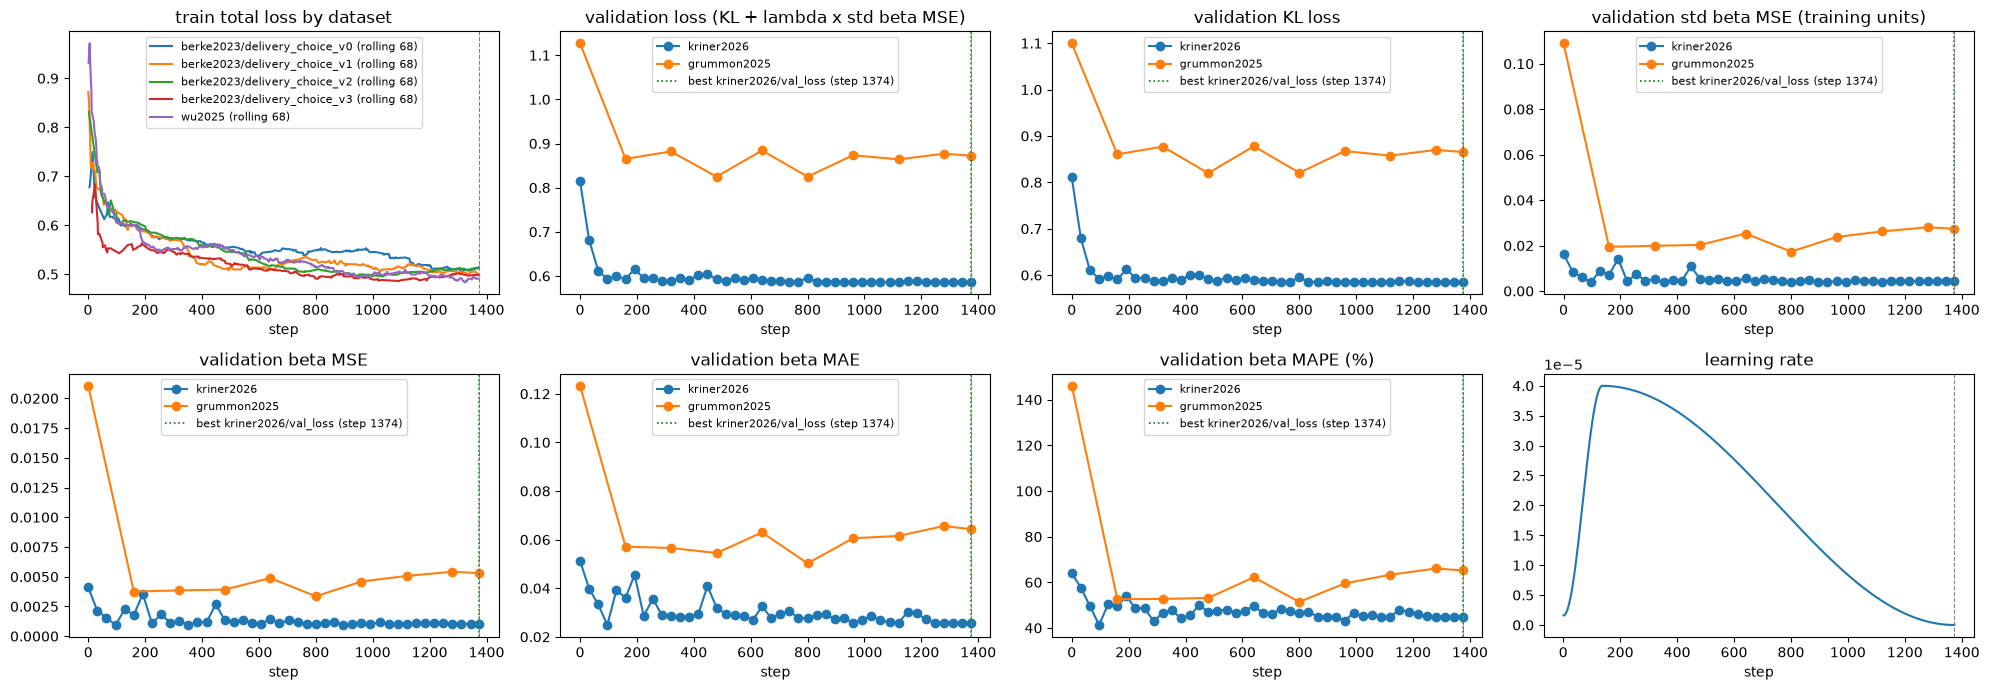

In [13]:
train_ce_population(0.25)


## λ = 1.0: population beta loss vs v12's sample beta loss at the same λ

v12 benchmark (Kev 4B, same regime):

| v12 run (best.pt by `kriner2026/val_loss`) | best step / 1,375 | Kriner KL | Kriner std beta MSE | Kriner ρ | Grummon KL | Grummon std beta MSE | Grummon ρ |
|---|---|---|---|---|---|---|---|
| untrained (step 0) | 0 | | 0.0164 | | | 0.1090 | |
| λ = 0 (CE only) | 160 | 0.5840 | **0.0034** | 0.930 | 0.8399 | **0.0161** | 0.9 |
| λ = 0.25 (CE + 0.25 × sample beta loss; interrupted at step 288) | 160 | 0.5862 | 0.0039 | 0.930 | 0.8340 | 0.0162 | 0.9 |
| λ = 1 (CE + 1 × sample beta loss) | 1,056 | 0.5844 | 0.0047 | 0.930 | 0.8981 | 0.0390 | 0.9 |

To beat: Kriner std beta MSE below 0.0034 (v12 λ = 0) and 0.0047 (v12 λ = 1), at Kriner KL no worse than about 0.584;
on Grummon, v12's λ = 1 best.pt (0.0390) is worse than its CE-only run (0.0161).

,wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choice_v3 | CE + lambda=1 x population betas
train_datasets,"[wu2025, berke2023/delivery_choice_v0, berke20..."
sample_size_by_dataset,"{'wu2025': 40, 'berke2023/delivery_choice_v0':..."
beta_lambda,1.0
lr,0.00004
num_epochs,1
eval_every_by_validator,"{'kriner2026': 32, 'grummon2025': 160}"
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,4
p0_chunk,32


berke2023/delivery_choice_v1: 11,481 tasks mod sample size 40 = 1, so each epoch has one sample of 41 tasks


,epoch,rows_seen,train_loss,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,kriner2026/eval_wall_sec,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.82712,0.01641,0.81071,0.00410,0.05127,63.94891,0.89510,1.20875,0.10899,1.09976,0.02105,0.12329,146.05853,0.80000,NaN,40.53544,317.60245,0.00000
32,1,1281,0.77991,0.70963,0.00877,0.70087,0.00219,0.04033,59.88389,0.93706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,41.41957,NaN,1739.45756
64,1,2561,0.57607,0.60985,0.00707,0.60277,0.00177,0.03437,47.07559,0.95804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00002,41.38235,NaN,1863.95940
96,1,3841,0.57677,0.59216,0.00290,0.58926,0.00072,0.02173,37.05139,0.93706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,41.42655,NaN,1989.75368
128,1,5121,0.58370,0.59110,0.00402,0.58708,0.00101,0.02572,40.74998,0.93007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.41652,NaN,2113.58850
160,1,6401,0.58280,0.59116,0.00522,0.58593,0.00131,0.03072,43.77068,0.95105,0.89012,0.01256,0.87756,0.00243,0.04365,40.15715,0.90000,0.00004,41.41779,312.66941,2240.19857
192,1,7681,0.56802,0.60494,0.00584,0.59909,0.00146,0.03265,47.78618,0.96503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.44259,NaN,2364.25886
224,1,8961,0.52534,0.60141,0.00492,0.59649,0.00123,0.02839,44.25044,0.93007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.41353,NaN,2490.73883
256,1,10241,0.55876,0.61174,0.01212,0.59962,0.00303,0.04342,53.00388,0.93007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.42611,NaN,2611.97405


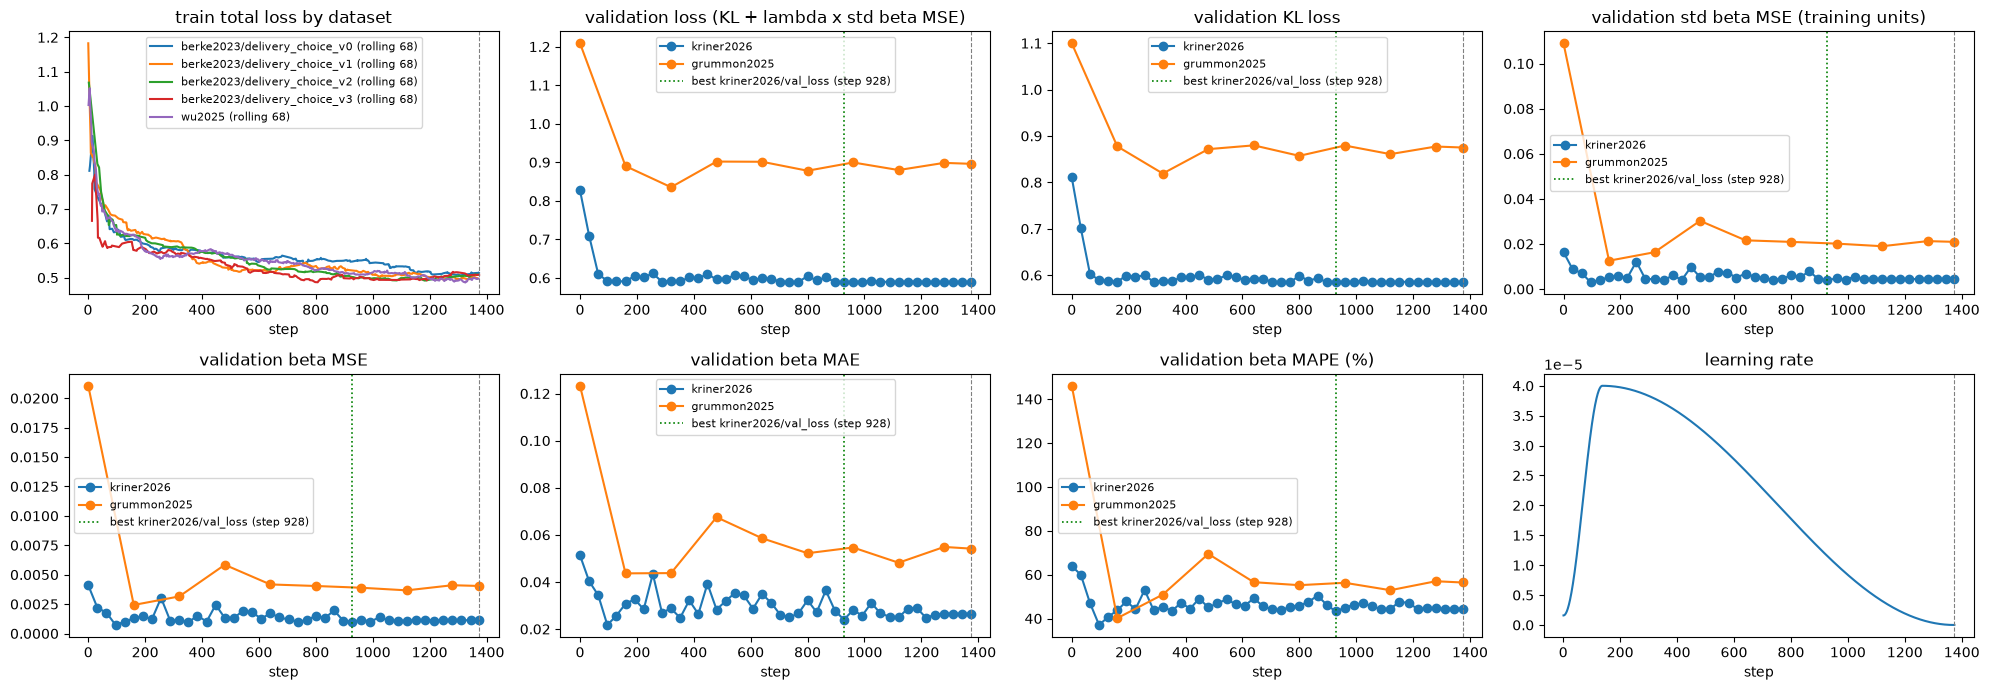

best.pt (step 928) validated at the end on: grummon2025


In [14]:
train_ce_population(1.0)


,wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choice_v3 | CE + lambda=0.025 x population betas
train_datasets,"[wu2025, berke2023/delivery_choice_v0, berke20..."
sample_size_by_dataset,"{'wu2025': 40, 'berke2023/delivery_choice_v0':..."
beta_lambda,0.025
lr,0.00004
num_epochs,1
eval_every_by_validator,"{'kriner2026': 32, 'grummon2025': 160}"
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,4
p0_chunk,32


berke2023/delivery_choice_v1: 11,481 tasks mod sample size 40 = 1, so each epoch has one sample of 41 tasks


,epoch,rows_seen,train_loss,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,kriner2026/eval_wall_sec,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.81112,0.01641,0.81071,0.00410,0.05127,63.94891,0.89510,1.10248,0.10899,1.09976,0.02105,0.12329,146.05853,0.80000,NaN,40.53544,317.60245,0.00000
32,1,1281,0.67237,0.66747,0.00889,0.66725,0.00222,0.04015,55.97572,0.93706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,41.34913,NaN,1739.03205
64,1,2561,0.55674,0.61081,0.00712,0.61063,0.00178,0.03491,48.49769,0.95804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00002,41.42742,NaN,1863.49868
96,1,3841,0.56756,0.59475,0.00479,0.59463,0.00120,0.02839,43.73695,0.92308,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,41.38357,NaN,1989.33989
128,1,5121,0.55407,0.60209,0.00973,0.60184,0.00243,0.04111,52.12943,0.92308,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.37697,NaN,2113.22590
160,1,6401,0.57810,0.58704,0.00433,0.58694,0.00108,0.02987,46.93806,0.95105,0.83734,0.01597,0.83694,0.00308,0.04944,45.11450,0.90000,0.00004,41.36194,312.60418,2239.85124
192,1,7681,0.54487,0.59862,0.00948,0.59838,0.00237,0.03929,48.82531,0.94406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.51959,NaN,2363.88524
224,1,8961,0.52112,0.59695,0.00593,0.59680,0.00148,0.03410,50.77120,0.93007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.44655,NaN,2490.50328
256,1,10241,0.53470,0.60310,0.00954,0.60286,0.00238,0.03899,53.02518,0.93007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,42.03994,NaN,2611.88982


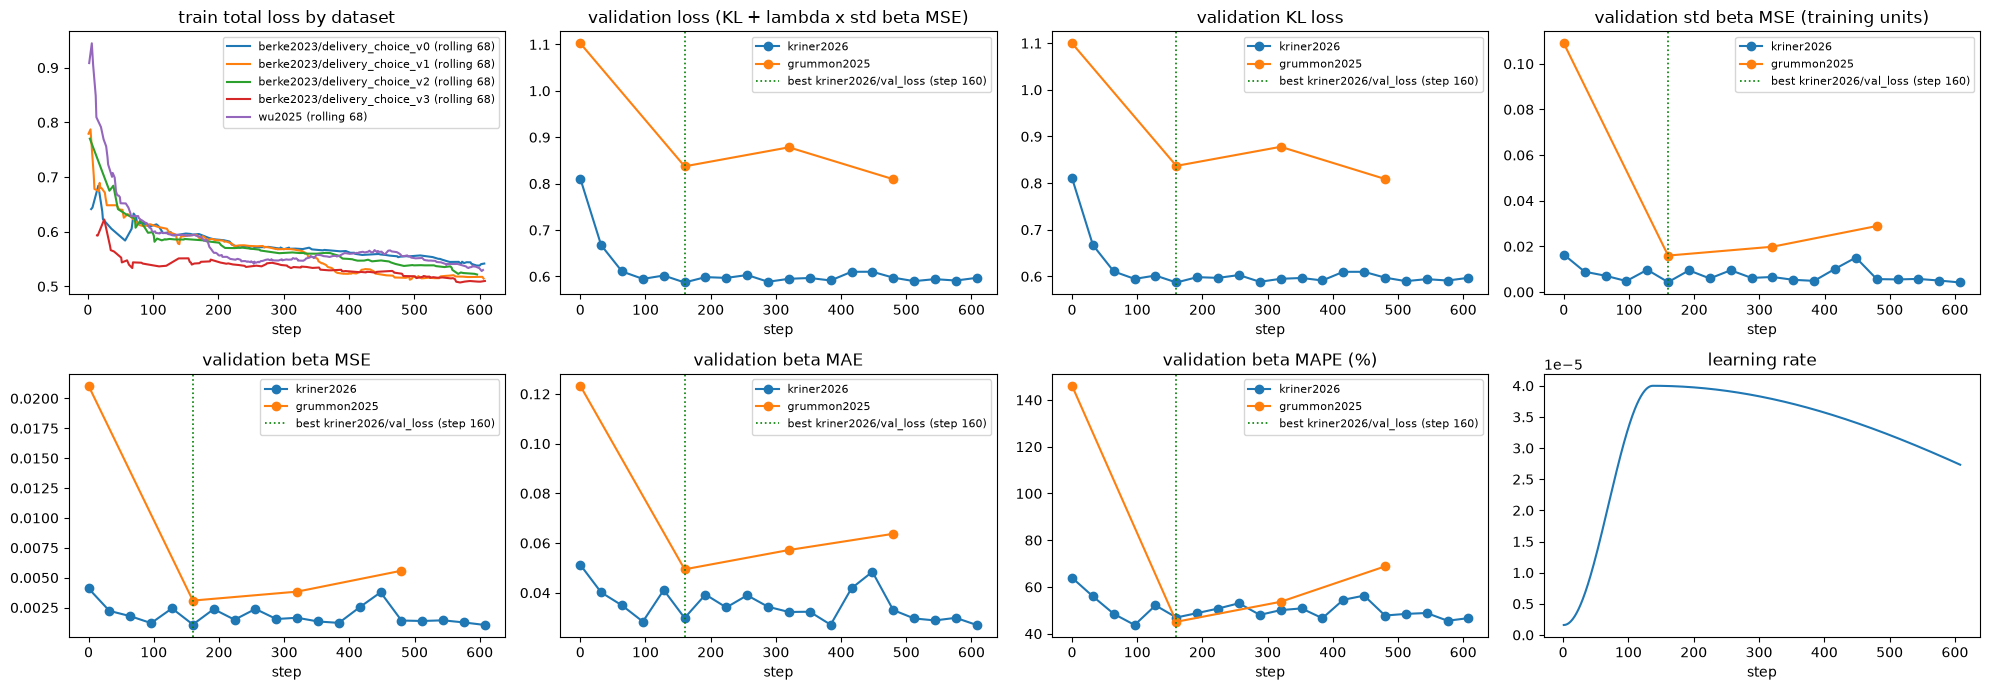

KeyboardInterrupt: 

In [15]:
train_ce_population(.025)


,wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choice_v3 | CE + lambda=2 x population betas
train_datasets,"[wu2025, berke2023/delivery_choice_v0, berke20..."
sample_size_by_dataset,"{'wu2025': 40, 'berke2023/delivery_choice_v0':..."
beta_lambda,2.0
lr,0.00004
num_epochs,1
eval_every_by_validator,"{'kriner2026': 32, 'grummon2025': 160}"
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,4
p0_chunk,32


berke2023/delivery_choice_v1: 11,481 tasks mod sample size 40 = 1, so each epoch has one sample of 41 tasks


,epoch,rows_seen,train_loss,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,kriner2026/eval_wall_sec,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.84352,0.01641,0.81071,0.00410,0.05127,63.94891,0.89510,1.31773,0.10899,1.09976,0.02105,0.12329,146.05853,0.80000,NaN,40.53544,317.60245,0.00000
32,1,1281,0.87733,0.73207,0.00909,0.71388,0.00227,0.04052,61.18653,0.93706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,41.84286,NaN,1753.99596
64,1,2561,0.60689,0.61831,0.00735,0.60362,0.00184,0.03281,42.86355,0.95804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00002,41.88074,NaN,1878.79295
96,1,3841,0.61988,0.60479,0.00646,0.59187,0.00162,0.03239,43.34367,0.94406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,41.78831,NaN,2004.85500
128,1,5121,0.58924,0.60027,0.00482,0.59062,0.00121,0.02716,45.38615,0.93007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,41.76724,NaN,2129.00477
160,1,6401,0.60609,0.61171,0.00783,0.59606,0.00196,0.03502,45.47677,0.95105,0.94863,0.03371,0.88120,0.00651,0.07357,70.71949,0.90000,0.00004,42.71703,317.58945,2256.61009
192,1,7681,0.58913,0.61512,0.00468,0.60575,0.00117,0.03013,47.52153,0.95105,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,43.95023,NaN,2381.23881
224,1,8961,0.53535,0.61096,0.00549,0.59998,0.00137,0.03036,48.19487,0.92308,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,45.43255,NaN,2514.09438
256,1,10241,0.58578,0.64590,0.01800,0.60991,0.00450,0.05278,61.23684,0.93007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,43.88381,NaN,2637.69334


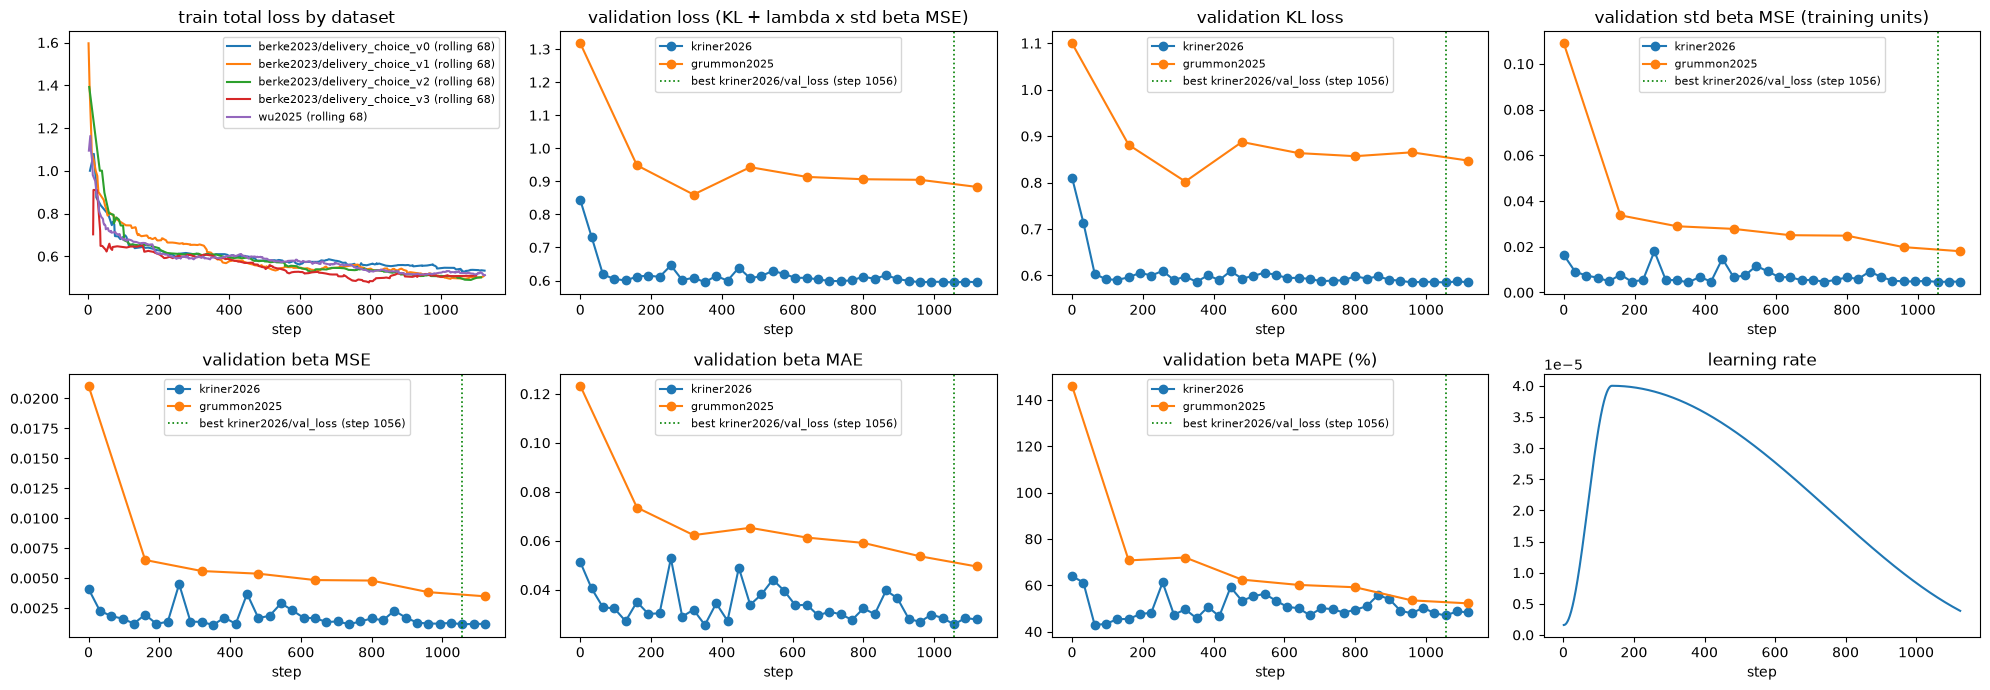

In [ ]:
train_ce_population(2.0)


In [ ]:
train_ce_population(4.0)


# Compare with v12 (Kev 4B, same regime, sample beta loss)

In [12]:
# Comparison read from the run folders on disk (needs only the first code cell, so it works without training in this
# session): one row per run, the validation of its best.pt. A run folder that does not exist yet is skipped with a
# warning; an unfinished run is shown with its best validation so far (status column).
import warnings

from beta_train.runs import read_run_json

OLD_LABEL = "v12"
OLD_RUNS_DIR = BETA_TRAINING_DIR / "runs" / "train-beta-v12-wu-berke-scale-4b"
OLD_RUN_NAMES = [
    "lambda=0_lr=4e-05_S=40_ep=1",
    "lambda=0.25_lr=4e-05_S=40_ep=1",
    "lambda=1_lr=4e-05_S=40_ep=1",
]
NEW_RUNS_DIR = BETA_TRAINING_DIR / "runs" / "train-beta-v14-wu-berke-ce-population-4b"
NEW_RUN_NAMES = [
    "lambda=0.25_lr=4e-05_S=40_ep=1",
    "lambda=1_lr=4e-05_S=40_ep=1",
]
COMPARE_VALIDATORS = ["kriner2026", "grummon2025"]
COMPARE_METRICS = ["kl_loss", "std_beta_mse", "beta_mse", "spearman_rho"]

run_sources = []   # (row label, run folder, loader)
for run_name in OLD_RUN_NAMES:
    run_sources.append((f"{OLD_LABEL} sample beta | {run_name}", OLD_RUNS_DIR / run_name, load_run))
for run_name in NEW_RUN_NAMES:
    run_sources.append((f"v14 population beta | {run_name}", NEW_RUNS_DIR / run_name, load_ce_population_run))

comparison_rows = []
for label, run_dir, load_saved_run in run_sources:
    if not (run_dir / "run.json").exists():
        warnings.warn(f"No saved run in {run_dir}; it is left out of the comparison")
        continue
    run_result = load_saved_run(run_dir)
    row = {"run": label, "status": read_run_json(run_dir)["status"], "best_step": run_result.best["step"]}
    for validator_name in COMPARE_VALIDATORS:
        for metric in COMPARE_METRICS:
            row[f"{validator_name}/{metric}"] = run_result.best_row[f"{validator_name}/{metric}"]
    comparison_rows.append(row)
if comparison_rows:
    display(pd.DataFrame(comparison_rows).set_index("run").round(5))
else:
    warnings.warn("No saved runs to compare")


/tmp/ipykernel_169629/455114622.py:32: UserWarning: No saved run in /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v14-wu-berke-ce-population-4b/lambda=0.25_lr=4e-05_S=40_ep=1; it is left out of the comparison
  warnings.warn(f"No saved run in {run_dir}; it is left out of the comparison")
/tmp/ipykernel_169629/455114622.py:32: UserWarning: No saved run in /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v14-wu-berke-ce-population-4b/lambda=1_lr=4e-05_S=40_ep=1; it is left out of the comparison
  warnings.warn(f"No saved run in {run_dir}; it is left out of the comparison")


,status,best_step,kriner2026/kl_loss,kriner2026/std_beta_mse,kriner2026/beta_mse,kriner2026/spearman_rho,grummon2025/kl_loss,grummon2025/std_beta_mse,grummon2025/beta_mse,grummon2025/spearman_rho
run,,,,,,,,,,
v12 sample beta | lambda=0_lr=4e-05_S=40_ep=1,finished,160,0.58396,0.00344,0.00086,0.93007,0.83993,0.01608,0.00311,0.9
v12 sample beta | lambda=0.25_lr=4e-05_S=40_ep=1,interrupted,160,0.58621,0.00387,0.00097,0.93007,0.83401,0.01623,0.00314,0.9
v12 sample beta | lambda=1_lr=4e-05_S=40_ep=1,finished,1056,0.58436,0.00469,0.00117,0.93007,0.89807,0.03897,0.00753,0.9
